# 08. 하이브리드 두 트랙 — 최지훈 B5~B7

제안서 3.3절. `07_cbf.ipynb`를 먼저 실행해서 `cbf` 예측값과 `results/cbf/{DS}_cbf_config.json`이 있어야 한다.

| 셀 | 트랙 | 내용 | 대략 (Video_Games) |
|---|---|---|---|
| 0 | | 설정 | 수 초 |
| 1 | | 데이터, 07·05 설정, **MF 학습** (혜림 님 설정·시드 그대로, Top-N 원점수용) | 6분 |
| 2 | 평점 | w 탐색 (valid RMSE) → test RMSE·MAE | 수 초 |
| 3 | 평점 | 구간별 w (cold / mid / active) | 수 초 |
| 4 | 평점 | 성공 기준 ①② 판정, 예측값 저장 | 1분 |
| 5 | Top-N | 신호 모델 준비 | 수 초 |
| 6 | Top-N | 가중치 탐색 (valid ③ HR@10, 66개 조합) | 셀 안에서 예상 시간 출력 |
| 7 | Top-N | test ①②③ 평가, 성공 기준 ③ 판정, 사용자별 hit 저장 | 5~10분 |
| 8 | | 설정·결과 저장 | 수 초 |

규칙: w와 Top-N 가중치는 **valid로만** 고르고 test는 마지막에 한 번만 쓴다 (docs/EVAL_RULES.md).

**Toys 일반화 (11/5)**: `DS = 'Toys_and_Games'`, `TRANSFER_FROM = 'Video_Games'` (07도 같은 설정으로 먼저 실행).
- 저장되는 `hybrid`·`hybrid_grp` 예측값과 판정은 **Video_Games에서 고른 w·구간별 w·Top-N 가중치를 그대로 적용한 결과**다 (성공 기준 ④)
- Toys에서 다시 고른 결과는 `*_retuned`로 같이 남겨 재튜닝 이득을 비교한다 (제안서 5.2절)
- Toys MF 예측값 파일이 없으면 1번 셀에서 학습한 MF로 `mf`, `mf_fb`를 만들어 저장한다
- Toys는 상품이 많아 6·7번 셀이 오래 걸린다. 시간이 부족하면 `RUN_RANK_SEARCH = False`(재튜닝 생략), `EVAL_SINGLES = False`(CBF·MF 단독 랭킹 생략)

In [1]:
# ===== 0. 설정 =====
import os, sys, subprocess, json, time, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO = '/content/team10-recsys'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/qhfl3644/team10-recsys.git', REPO], check=True)
    else:
        subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)
except ImportError:
    REPO = os.environ.get('TEAM10_REPO', '..')
sys.path.insert(0, REPO)
from config import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import src.models.cbf as cbf_mod, src.models.hybrid as hyb_mod
importlib.reload(cbf_mod); importlib.reload(hyb_mod)
from src.eval import metrics as M
from src.models.baselines import BASELINES
from src.models.mf import MF
from src.models.cbf import CBF, load_tfidf
from src.models.hybrid import (W_GRID, blend, search_w, search_w_by_group, blend_by_group,
                               RankHybrid, weight_grid, search_rank_weights)

DS = 'Toys_and_Games'
TRANSFER_FROM = 'Video_Games'              # Toys 일반화 때 'Video_Games'
RUN_RANK_SEARCH = True                     # 6번 셀 Top-N 가중치 탐색 (적용 모드에서는 재튜닝 비교용)
EVAL_SINGLES = False                        # 7번 셀에서 CBF·MF 단독 랭킹도 평가
OUT = f'{RESULT_DIR}/hybrid'
os.makedirs(OUT, exist_ok=True)
CHUNK = 256 if DS == 'Video_Games' else 64     # Toys는 상품이 많아 한 번에 처리하는 사용자를 줄임
parse_k = lambda s: None if str(s) == 'all' else int(s)

TR = None
if TRANSFER_FROM:
    with open(f'{OUT}/{TRANSFER_FROM}_hybrid_config.json', encoding='utf-8') as f:
        TR = json.load(f)
    print(f'적용 모드: {TRANSFER_FROM}의 w={TR["rating_w"]}, 구간별 w={TR["rating_w_group"]}, Top-N 가중치={TR["rank_weights"]}를 그대로 적용')
print('준비 완료:', DS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
적용 모드: Video_Games의 w=0.85, 구간별 w={'cold(3-4)': 0.9, 'mid(5-9)': 0.85, 'active(10+)': 0.8}, Top-N 가중치={'pop': 0.7, 'cbf': 0.3, 'mf': 0.0}를 그대로 적용
준비 완료: Toys_and_Games


## 1. 데이터, 앞 단계 설정, MF 학습

- `07`의 CBF 설정(k, score_k)과 TF-IDF 행렬
- MF 설정: `results/mf/{DS}_mf_config.json` → 없으면 적용 모드의 원래 데이터셋 설정 → 없으면 혜림 님 05의 값(16, 0.01, 0.1)
- MF는 혜림 님이 예측값 파일만 저장해서, Top-N 원점수를 위해 **같은 설정·같은 시드로 다시 학습**한다.
  예측값 파일이 있으면 다시 학습한 결과와 같은지 확인하고, 없으면 이 MF로 `mf`·`mf_fb`를 만들어 저장한다.

In [2]:
# ===== 1. 데이터 + MF =====
t0 = time.time()
data = M.load_data(DS)
with open(f'{RESULT_DIR}/cbf/{DS}_cbf_config.json', encoding='utf-8') as f:
    cbf_cfg = json.load(f)
CBF_K, SCORE_K = parse_k(cbf_cfg['k']), parse_k(cbf_cfg['score_k'])
mf_cfg = dict(k=16, lr=0.01, reg=0.1)
for src_ds in [DS, TRANSFER_FROM]:
    pth = f'{RESULT_DIR}/mf/{src_ds}_mf_config.json' if src_ds else None
    if pth and os.path.exists(pth):
        mf_cfg = json.load(open(pth, encoding='utf-8')); mf_cfg['_from'] = src_ds; break
print(f'CBF 설정 (07): k={cbf_cfg["k"]}, score_k={cbf_cfg["score_k"]}' + (f' ({cbf_cfg["transfer_from"]}에서 적용)' if cbf_cfg.get('transfer_from') else ''))
print(f'MF 설정: k={mf_cfg["k"]}, lr={mf_cfg["lr"]}, reg={mf_cfg["reg"]}  (출처: {mf_cfg.get("_from", "기본값")})')

mf = MF(k=int(mf_cfg['k']), lr=float(mf_cfg['lr']), reg=float(mf_cfg['reg']), epochs=60, patience=5, seed=SEED)
mf.fit(data.train, data.n_users, data.n_items, valid=data.valid)

P = {}
for split in ['valid', 'test']:
    df = getattr(data, split)
    p_new = mf.predict(df['uidx'].values, df['iidx'].values)
    cbf_p = M.load_predictions(DS, 'cbf', split, df)
    if os.path.exists(f'{PRED_DIR}/{DS}/mf_{split}.parquet'):
        p_mf = M.load_predictions(DS, 'mf', split, df)
        d = np.abs(p_new - p_mf).max()
        print(f'  {split}: 다시 학습한 MF와 저장된 mf 예측 차이 최대 {d:.2e} → {"같음" if d < 1e-6 else "조금 다름 (저장본을 평점 트랙에 사용)"}')
    else:
        p_mf = p_new
        print('  저장:', M.save_predictions(DS, 'mf', split, df, p_mf), '(MF 예측값 파일이 없어 여기서 만듦)')
    if os.path.exists(f'{PRED_DIR}/{DS}/mf_fb_{split}.parquet'):
        p_fb = M.load_predictions(DS, 'mf_fb', split, df)
    else:
        un = ~data.seen_mask(df)
        p_fb = p_mf.copy(); p_fb[un] = cbf_p[un]
        print('  저장:', M.save_predictions(DS, 'mf_fb', split, df, p_fb), f'(CBF로 바꾼 행 {int(un.sum())}개)')
    P[split] = {'mf': p_mf, 'mf_fb': p_fb, 'cbf': cbf_p}
yv, yt = data.valid['rating'].values, data.test['rating'].values
gv, gt = data.group_of(data.valid['uidx'].values), data.group_of(data.test['uidx'].values)
for split, y in [('valid', yv), ('test', yt)]:
    print(f'  {split}: ' + ', '.join(f'{m} RMSE {M.rmse(y, P[split][m]):.4f}' for m in ['mf', 'mf_fb', 'cbf']))
print(f'({time.time()-t0:.0f}초)')

CBF 설정 (07): k=all, score_k=3 (Video_Games에서 적용)
MF 설정: k=16, lr=0.01, reg=0.1  (출처: Video_Games)
    epoch   1  valid RMSE 1.0948
    epoch   2  valid RMSE 1.0779
    epoch   3  valid RMSE 1.0664
    epoch   5  valid RMSE 1.0508
    epoch  10  valid RMSE 1.0320
    epoch  15  valid RMSE 1.0251
    epoch  20  valid RMSE 1.0232
    epoch  25  valid RMSE 1.0236
    조기 종료: 26에폭 (최저 21에폭, valid RMSE 1.0231)
  저장: /content/drive/MyDrive/Team10_RecSys/predictions/Toys_and_Games/mf_valid.parquet (MF 예측값 파일이 없어 여기서 만듦)
  저장: /content/drive/MyDrive/Team10_RecSys/predictions/Toys_and_Games/mf_fb_valid.parquet (CBF로 바꾼 행 720개)
  저장: /content/drive/MyDrive/Team10_RecSys/predictions/Toys_and_Games/mf_test.parquet (MF 예측값 파일이 없어 여기서 만듦)
  저장: /content/drive/MyDrive/Team10_RecSys/predictions/Toys_and_Games/mf_fb_test.parquet (CBF로 바꾼 행 1441개)
  valid: mf RMSE 1.0231, mf_fb RMSE 1.0232, cbf RMSE 1.1403
  test: mf RMSE 1.1472, mf_fb RMSE 1.1474, cbf RMSE 1.2696
(1157초)


## 2. 평점 예측 트랙: w 탐색

r_hat = w · MF + (1 − w) · CBF,  w = 0, 0.05, …, 1 (21개). **valid RMSE가 가장 낮은 w**를 고른다.
w = 1이면 MF만, w = 0이면 CBF만 쓰는 것과 같다. 적용 모드에서는 원래 데이터셋의 w를 쓰고 여기서 고른 w는 비교용이다.

In [3]:
# ===== 2. w 탐색 =====
w_table, W_RETUNED = search_w(yv, P['valid']['mf_fb'], P['valid']['cbf'])
BEST_W = float(TR['rating_w']) if TR else W_RETUNED
print(w_table.iloc[::2].round(4).to_string(index=False))
print(f'\nvalid로 고른 w = {W_RETUNED:.2f}  (valid RMSE {w_table["rmse"].min():.4f})')
p_hyb = {s: blend(P[s]['mf_fb'], P[s]['cbf'], BEST_W) for s in ['valid', 'test']}
if TR:
    p_hyb_rt = {s: blend(P[s]['mf_fb'], P[s]['cbf'], W_RETUNED) for s in ['valid', 'test']}
    print(f'적용하는 w = {BEST_W:.2f} ({TRANSFER_FROM}): test RMSE {M.rmse(yt, p_hyb["test"]):.4f} / 재튜닝 w {W_RETUNED:.2f}: {M.rmse(yt, p_hyb_rt["test"]):.4f}'
          f'  → 재튜닝 이득 {M.rmse(yt, p_hyb["test"]) - M.rmse(yt, p_hyb_rt["test"]):+.4f}')
print(f'test: 하이브리드(w={BEST_W:.2f}) RMSE {M.rmse(yt, p_hyb["test"]):.4f}  MAE {M.mae(yt, p_hyb["test"]):.4f}  '
      f'| MF(fb) {M.rmse(yt, P["test"]["mf_fb"]):.4f}  | CBF {M.rmse(yt, P["test"]["cbf"]):.4f}')

  w   rmse    mae
0.0 1.1403 0.6701
0.1 1.1165 0.6685
0.2 1.0951 0.6673
0.3 1.0761 0.6666
0.4 1.0599 0.6664
0.5 1.0464 0.6667
0.6 1.0357 0.6675
0.7 1.0280 0.6690
0.8 1.0234 0.6712
0.9 1.0218 0.6741
1.0 1.0232 0.6776

valid로 고른 w = 0.90  (valid RMSE 1.0218)
적용하는 w = 0.85 (Video_Games): test RMSE 1.1495 / 재튜닝 w 0.90: 1.1481  → 재튜닝 이득 +0.0014
test: 하이브리드(w=0.85) RMSE 1.1495  MAE 0.7550  | MF(fb) 1.1474  | CBF 1.2696


## 3. 구간별 w

가설: **평점이 적은 사용자일수록 CBF가 유리하다** → cold(3~4) 구간의 w가 가장 작게(CBF 비중이 크게) 나와야 한다.
가설이라 미리 정하지 않고 구간마다 valid로 고른다.

  cold(3-4)    valid로 고른 w = 0.90  (valid RMSE 1.0434, n=212,587)  | 적용하는 w = 0.90
  mid(5-9)     valid로 고른 w = 0.90  (valid RMSE 1.0141, n=149,818)  | 적용하는 w = 0.85
  active(10+)  valid로 고른 w = 0.85  (valid RMSE 0.9701, n=69,859)  | 적용하는 w = 0.80

RMSE (test)
model        global_mean  user_mean  item_mean   mf_fb     cbf  hybrid  hybrid_grp  hybrid_retuned  hybrid_grp_retuned
group                                                                                                                 
all               1.2566     1.2338     1.2173  1.1474  1.2696  1.1495      1.1488          1.1481              1.1482
cold(3-4)         1.2782     1.2811     1.2346  1.1715  1.3242  1.1741      1.1723          1.1723              1.1723
mid(5-9)          1.2554     1.2107     1.2139  1.1403  1.2449  1.1427      1.1427          1.1414              1.1414
active(10+)       1.1914     1.1316     1.1708  1.0868  1.1459  1.0869      1.0877          1.0865              1.0869


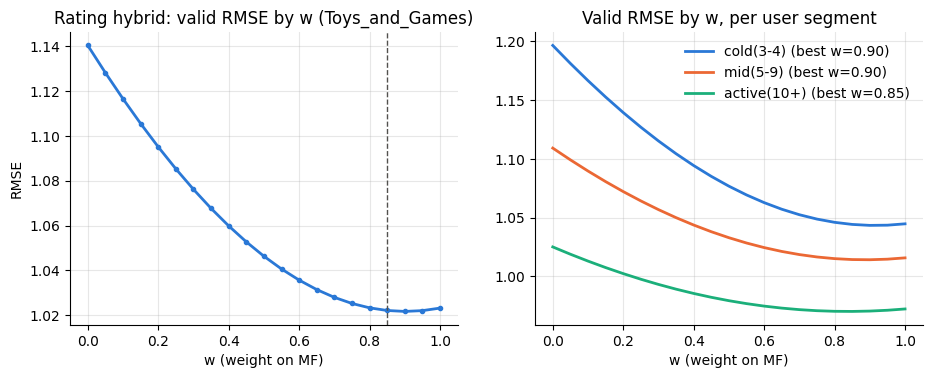

In [4]:
# ===== 3. 구간별 w =====
wg_table, W_GROUP_RETUNED = search_w_by_group(yv, P['valid']['mf_fb'], P['valid']['cbf'], gv)
W_GROUP = {g: float(w) for g, w in TR['rating_w_group'].items()} if TR else W_GROUP_RETUNED
for g in M.GROUPS:
    r = wg_table[(wg_table.group == g)]
    extra = f'  | 적용하는 w = {W_GROUP[g]:.2f}' if TR else ''
    print(f'  {g:12s} valid로 고른 w = {W_GROUP_RETUNED[g]:.2f}  (valid RMSE {r["rmse"].min():.4f}, n={int(r["n"].iloc[0]):,}){extra}')
p_hyb_g = {s: blend_by_group(P[s]['mf_fb'], P[s]['cbf'], g, W_GROUP) for s, g in [('valid', gv), ('test', gt)]}
if TR:
    p_hyb_g_rt = {s: blend_by_group(P[s]['mf_fb'], P[s]['cbf'], g, W_GROUP_RETUNED) for s, g in [('valid', gv), ('test', gt)]}

base = {k: c().fit(data.train, data.n_users, data.n_items) for k, c in BASELINES.items() if k != 'popularity'}
ut, it = data.test['uidx'].values, data.test['iidx'].values
p_base = {k: m.predict(ut, it) for k, m in base.items()}
tbl_preds = {**p_base, 'mf_fb': P['test']['mf_fb'], 'cbf': P['test']['cbf'], 'hybrid': p_hyb['test'], 'hybrid_grp': p_hyb_g['test']}
if TR:
    tbl_preds.update({'hybrid_retuned': p_hyb_rt['test'], 'hybrid_grp_retuned': p_hyb_g_rt['test']})
rt = M.rating_table(tbl_preds, data.test, data)
print('\nRMSE (test)')
print(rt[rt.scope == 'all'].pivot_table(index='group', columns='model', values='rmse', sort=False)[list(tbl_preds)].round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(w_table['w'], w_table['rmse'], marker='o', markersize=3, linewidth=2, color='#2a78d6')
axes[0].axvline(BEST_W, color='#52514e', linestyle='--', linewidth=1)
axes[0].set_title(f'Rating hybrid: valid RMSE by w ({DS})'); axes[0].set_xlabel('w (weight on MF)'); axes[0].set_ylabel('RMSE')
colors = {'cold(3-4)': '#2a78d6', 'mid(5-9)': '#eb6834', 'active(10+)': '#1baf7a'}
for g in M.GROUPS:
    r = wg_table[wg_table.group == g]
    axes[1].plot(r['w'], r['rmse'], linewidth=2, color=colors[g], label=f'{g} (best w={W_GROUP_RETUNED[g]:.2f})')
axes[1].set_title('Valid RMSE by w, per user segment'); axes[1].set_xlabel('w (weight on MF)'); axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False); ax.grid(alpha=0.3)
fig.savefig(f'{OUT}/{DS}_rating_w.png', dpi=200, bbox_inches='tight'); plt.show()

## 4. 성공 기준 ①②(④) 판정 + 예측값 저장

- 기준 ①(Video_Games) / ④(Toys, 적용 모드): 하이브리드 RMSE가 기준 모델 3개 모두보다 낮을 것 (점추정)
- 기준 ②: cold(3~4) 구간에서 (단일 방식 − 하이브리드)의 95% CI 상한 ≥ 0 (MF는 fallback 버전)
- 판정은 율이 님 함수(`metrics.criterion_*`)를 그대로 쓴다. 최종 집계는 율이 님이 같은 파일로 다시 한다.

In [5]:
# ===== 4. 판정 + 저장 =====
cname = '④' if TR else '①'
c1 = M.criterion_rating_vs_baselines(p_hyb['test'], p_base, data.test, data)
print(f'[기준 {cname}] 하이브리드 vs 기준 모델 3개: {"통과" if c1.attrs["passed"] else "미통과"}')
print(c1[['baseline', 'rmse_model', 'rmse_baseline', 'ci_lo', 'ci_hi', 'passed']].round(4).to_string(index=False))
c2_all = {}
for name, ph in [('hybrid', p_hyb['test']), ('hybrid_grp', p_hyb_g['test'])]:
    c2 = M.criterion_cold_hybrid(ph, {'mf_fb': P['test']['mf_fb'], 'cbf': P['test']['cbf']}, data.test, data)
    c2_all[name] = c2
    print(f'\n[기준 ②] {name}: {"통과" if c2.attrs["passed"] else "미통과"}')
    print(c2[['single', 'n', 'rmse_hybrid', 'rmse_single', 'single_minus_hybrid', 'ci_lo', 'ci_hi', 'passed']].round(4).to_string(index=False))

for split in ['valid', 'test']:
    df = getattr(data, split)
    print(' 저장:', M.save_predictions(DS, 'hybrid', split, df, p_hyb[split]))
    print(' 저장:', M.save_predictions(DS, 'hybrid_grp', split, df, p_hyb_g[split]))
    if TR:
        print(' 저장:', M.save_predictions(DS, 'hybrid_retuned', split, df, p_hyb_rt[split]))
        print(' 저장:', M.save_predictions(DS, 'hybrid_grp_retuned', split, df, p_hyb_g_rt[split]))

[기준 ④] 하이브리드 vs 기준 모델 3개: 통과
   baseline  rmse_model  rmse_baseline  ci_lo  ci_hi  passed
global_mean      1.1495         1.2566 0.1053 0.1090    True
  user_mean      1.1495         1.2338 0.0829 0.0856    True
  item_mean      1.1495         1.2173 0.0659 0.0695    True

[기준 ②] hybrid: 미통과
single      n  rmse_hybrid  rmse_single  single_minus_hybrid   ci_lo   ci_hi  passed
 mf_fb 212587       1.1741       1.1715              -0.0026 -0.0031 -0.0021   False
   cbf 212587       1.1741       1.3242               0.1502  0.1476  0.1529    True

[기준 ②] hybrid_grp: 미통과
single      n  rmse_hybrid  rmse_single  single_minus_hybrid   ci_lo   ci_hi  passed
 mf_fb 212587       1.1723       1.1715              -0.0009 -0.0012 -0.0006   False
   cbf 212587       1.1723       1.3242               0.1519  0.1491  0.1548    True
 저장: /content/drive/MyDrive/Team10_RecSys/predictions/Toys_and_Games/hybrid_valid.parquet
 저장: /content/drive/MyDrive/Team10_RecSys/predictions/Toys_and_Games/hybrid_grp_val

## 5. Top-N 트랙: 신호 모델 준비

- 인기도: log(1 + train 평점 수) (율이 님 `Popularity`)
- CBF 유사도 원점수: 07에서 정한 score_k
- MF 원점수: 1번 셀에서 학습한 MF (clip 없음)

In [6]:
# ===== 5. 신호 모델 =====
X = load_tfidf(cbf_cfg['tfidf_path'])
cbf = CBF(X, k=CBF_K, score_k=SCORE_K).fit(data.train, data.n_users, data.n_items)
pop = BASELINES['popularity']().fit(data.train, data.n_users, data.n_items)
SIGNALS = {'pop': pop, 'cbf': cbf, 'mf': mf}
print('신호:', list(SIGNALS))

신호: ['pop', 'cbf', 'mf']


## 6. Top-N 가중치 탐색 (valid, 프로토콜 ③)

score = a·z(인기도) + b·z(CBF) + c·z(MF),  a + b + c = 1, 0.1 간격 66개 조합.
z는 사용자마다 전체 상품 안에서 표준화한 값. **valid ③(p3_users 1만 명)의 HR@10**이 가장 높은 조합을 고른다.
(1, 0, 0)이 인기도 기준 모델, (0, 1, 0)이 CBF 단독, (0, 0, 1)이 MF 단독이다.
적용 모드에서는 원래 데이터셋의 가중치를 쓰고, 여기서 고른 가중치는 재튜닝 비교용이다.

먼저 사용자 한 묶음으로 시간을 재고 전체 예상 시간을 출력한다.

In [7]:
# ===== 6-1. 시간 측정 =====
p3 = M.load_p3_users(DS)
GRID = weight_grid(list(SIGNALS), step=0.1)
if RUN_RANK_SEARCH:
    t0 = time.time()
    _ = search_rank_weights(SIGNALS, data, 'valid', p3[:CHUNK], GRID, chunk=CHUNK, verbose=False)
    per = (time.time() - t0) / CHUNK
    print(f'조합 {len(GRID)}개, 사용자 1명당 {per*1000:.0f}ms → {len(p3):,}명 예상 {per*len(p3)/60:.1f}분')
else:
    print('RUN_RANK_SEARCH = False → 가중치 탐색을 건너뛴다')

조합 66개, 사용자 1명당 102ms → 10,000명 예상 17.0분


In [8]:
# ===== 6-2. 가중치 탐색 =====
rw_table = pd.DataFrame()
RANK_W_RETUNED = None
if RUN_RANK_SEARCH:
    t0 = time.time()
    rw_table, _ = search_rank_weights(SIGNALS, data, 'valid', p3, GRID, chunk=CHUNK)
    rw_table = rw_table.sort_values(['HR10', 'NDCG10'], ascending=False).reset_index(drop=True)
    best = rw_table.iloc[0]
    RANK_W_RETUNED = {n: float(best[f'w_{n}']) for n in SIGNALS}
    single = rw_table[(rw_table[[f'w_{n}' for n in SIGNALS]] == 1).any(axis=1)]
    print('상위 10개 조합')
    print(rw_table.head(10).round(4).to_string(index=False))
    print('\n신호 하나만 쓴 경우')
    print(single.round(4).to_string(index=False))
    print(f'\nvalid로 고른 가중치: {RANK_W_RETUNED}  (valid ③ HR@10 {best["HR10"]:.4f})  ({time.time()-t0:.0f}초)')
RANK_W = {n: float(v) for n, v in TR['rank_weights'].items()} if TR else RANK_W_RETUNED
assert RANK_W is not None, '적용 모드가 아니면 RUN_RANK_SEARCH = True여야 가중치를 고를 수 있습니다'
print(f'test 평가에 쓰는 가중치: {RANK_W}' + (f' ({TRANSFER_FROM}에서 고른 값)' if TR else ''))

  64/10,000명 (6초)
  704/10,000명 (63초)
  1,344/10,000명 (120초)
  1,984/10,000명 (179초)
  2,624/10,000명 (235초)
  3,264/10,000명 (293초)
  3,904/10,000명 (348초)
  4,544/10,000명 (405초)
  5,184/10,000명 (462초)
  5,824/10,000명 (520초)
  6,464/10,000명 (576초)
  7,104/10,000명 (634초)
  7,744/10,000명 (691초)
  8,384/10,000명 (746초)
  9,024/10,000명 (807초)
  9,664/10,000명 (861초)
상위 10개 조합
 w_pop  w_cbf  w_mf   HR10  NDCG10
   0.5    0.3   0.2 0.0352  0.0201
   0.4    0.3   0.3 0.0349  0.0195
   0.6    0.4   0.0 0.0348  0.0199
   0.6    0.3   0.1 0.0346  0.0200
   0.5    0.4   0.1 0.0345  0.0196
   0.4    0.4   0.2 0.0343  0.0192
   0.4    0.2   0.4 0.0342  0.0189
   0.7    0.3   0.0 0.0336  0.0194
   0.3    0.2   0.5 0.0330  0.0182
   0.5    0.5   0.0 0.0328  0.0190

신호 하나만 쓴 경우
 w_pop  w_cbf  w_mf   HR10  NDCG10
   0.0    1.0   0.0 0.0253  0.0142
   1.0    0.0   0.0 0.0055  0.0027
   0.0    0.0   1.0 0.0002  0.0001

valid로 고른 가중치: {'pop': 0.5, 'cbf': 0.3, 'mf': 0.2}  (valid ③ HR@10 0.0352)  (892초)
test 평가에

## 7. test 평가 (①②③) + 성공 기준 ③ + 사용자별 hit 저장

율이 님 `metrics.ranking_eval`로 계산한다. 규칙대로 ①②도 p3_users 1만 명으로 잘라서 본다.
기준 ③: 프로토콜 ③에서 (하이브리드 − 인기도) HR@10 차이의 95% CI 하한 > 0이면 통과.
사용자별 hit(0/1)는 `results/hybrid/{DS}_ranking_hits_test.parquet`에 저장한다 (율이 님 신뢰구간 계산용, EVAL_RULES 규칙 1).

In [9]:
# ===== 7. test 평가 =====
t0 = time.time()
models = {'popularity': pop}
if EVAL_SINGLES:
    models.update({'cbf': cbf, 'mf': mf})
models['rank_hybrid'] = RankHybrid(SIGNALS, RANK_W)
if TR and RANK_W_RETUNED is not None and RANK_W_RETUNED != RANK_W:
    models['rank_hybrid_retuned'] = RankHybrid(SIGNALS, RANK_W_RETUNED)
rank_table, hits = M.ranking_eval(models, data, 'test', users=p3, chunk=CHUNK)
print(rank_table.pivot_table(index='model', columns='protocol', values='HR10', sort=False).round(4).to_string())
c3 = M.criterion_topn_vs_popularity(hits, hybrid='rank_hybrid')
print(f'\n[기준 ③] 하이브리드 HR@10 {c3["hr_hybrid"]:.4f} vs 인기도 {c3["hr_popularity"]:.4f}, '
      f'차이 {c3["hybrid_minus_popularity"]:+.4f} (95% CI {c3["ci_lo"]:+.4f} ~ {c3["ci_hi"]:+.4f}) → {"통과" if c3["passed"] else "미통과"}')
if 'rank_hybrid_retuned' in models:
    c3r = M.criterion_topn_vs_popularity(hits, hybrid='rank_hybrid_retuned')
    print(f'(재튜닝 가중치) 하이브리드 HR@10 {c3r["hr_hybrid"]:.4f}, 차이 {c3r["hybrid_minus_popularity"]:+.4f} '
          f'(95% CI {c3r["ci_lo"]:+.4f} ~ {c3r["ci_hi"]:+.4f})')

# 구간별 ③ HR@10 (콜드스타트 분석)
grp = pd.Series(data.group_of(p3), index=p3)
seg = pd.DataFrame({m: hits[(m, 'p3')].groupby(grp).mean() for m in models}).reindex(M.GROUPS)
print('\n프로토콜 ③ HR@10, 사용자 구간별 (test)')
print(seg.round(4).to_string())

# 사용자별 hit 저장 (율이 님 부트스트랩용)
hl = pd.concat([pd.DataFrame({'model': m, 'protocol': p, 'uidx': s.index.values, 'hit': s.values})
                for (m, p), s in hits.items()], ignore_index=True)
hl.insert(0, 'dataset', DS)
hl.to_parquet(f'{OUT}/{DS}_ranking_hits_test.parquet', index=False)
print(f'\n사용자별 hit {len(hl):,}행 저장: {OUT}/{DS}_ranking_hits_test.parquet  ({time.time()-t0:.0f}초)')

protocol                 p1      p2      p3
model                                      
popularity           0.4266  0.1342  0.0038
rank_hybrid          0.5234  0.2824  0.0171
rank_hybrid_retuned  0.5185  0.2995  0.0170

[기준 ③] 하이브리드 HR@10 0.0171 vs 인기도 0.0038, 차이 +0.0133 (95% CI +0.0106 ~ +0.0160) → 통과
(재튜닝 가중치) 하이브리드 HR@10 0.0170, 차이 +0.0132 (95% CI +0.0103 ~ +0.0160)

프로토콜 ③ HR@10, 사용자 구간별 (test)
             popularity  rank_hybrid  rank_hybrid_retuned
cold(3-4)        0.0027       0.0186               0.0172
mid(5-9)         0.0046       0.0186               0.0200
active(10+)      0.0056       0.0093               0.0099

사용자별 hit 90,000행 저장: /content/drive/MyDrive/Team10_RecSys/results/hybrid/Toys_and_Games_ranking_hits_test.parquet  (1151초)


## 8. 설정·결과 저장

In [10]:
# ===== 8. 저장 =====
tables = [(w_table, 'rating_w'), (wg_table, 'rating_w_group'), (rt, 'rating_test'),
          (rank_table, 'ranking_test'), (seg.reset_index(), 'ranking_test_by_group')]
if len(rw_table):
    tables.append((rw_table, 'rank_weights_valid'))
for t, name in tables:
    t = t.copy(); t.insert(0, 'dataset', DS); t.to_csv(f'{OUT}/{DS}_{name}.csv', index=False)
cfg = dict(dataset=DS, transfer_from=TRANSFER_FROM,
           cbf=dict(k=cbf_cfg['k'], score_k=cbf_cfg['score_k']), mf=dict(k=mf_cfg['k'], lr=mf_cfg['lr'], reg=mf_cfg['reg']),
           rating_w=BEST_W, rating_w_group=W_GROUP, rank_weights=RANK_W,
           retuned=dict(rating_w=W_RETUNED, rating_w_group=W_GROUP_RETUNED, rank_weights=RANK_W_RETUNED),
           test=dict(hybrid_rmse=M.rmse(yt, p_hyb['test']), hybrid_mae=M.mae(yt, p_hyb['test']),
                     hybrid_grp_rmse=M.rmse(yt, p_hyb_g['test']),
                     criterion_rating=bool(c1.attrs['passed']),
                     criterion2={k: bool(v.attrs['passed']) for k, v in c2_all.items()},
                     criterion3=c3))
M.save_json(cfg, f'{OUT}/{DS}_hybrid_config.json')
print(json.dumps(cfg, ensure_ascii=False, indent=1, default=str))
print(f'\n저장 위치: {OUT}')

{
 "dataset": "Toys_and_Games",
 "transfer_from": "Video_Games",
 "cbf": {
  "k": "all",
  "score_k": "3"
 },
 "mf": {
  "k": 16,
  "lr": 0.01,
  "reg": 0.1
 },
 "rating_w": 0.85,
 "rating_w_group": {
  "cold(3-4)": 0.9,
  "mid(5-9)": 0.85,
  "active(10+)": 0.8
 },
 "rank_weights": {
  "pop": 0.7,
  "cbf": 0.3,
  "mf": 0.0
 },
 "retuned": {
  "rating_w": 0.9,
  "rating_w_group": {
   "mid(5-9)": 0.9,
   "cold(3-4)": 0.9,
   "active(10+)": 0.85
  },
  "rank_weights": {
   "pop": 0.5,
   "cbf": 0.3,
   "mf": 0.2
  }
 },
 "test": {
  "hybrid_rmse": 1.1495246292351395,
  "hybrid_mae": 0.7549504376303436,
  "hybrid_grp_rmse": 1.1487798303330607,
  "criterion_rating": true,
  "criterion2": {
   "hybrid": false,
   "hybrid_grp": false
  },
  "criterion3": {
   "protocol": "p3",
   "n_users": 10000,
   "hr_hybrid": 0.0171,
   "hr_popularity": 0.0038,
   "hybrid_minus_popularity": 0.013300000000000001,
   "ci_lo": 0.010600000000000002,
   "ci_hi": 0.015999999999999997,
   "passed": true
  }
 }
